In [1]:
from __future__ import annotations
from typing import Literal

import sys,os
sys.path.insert(0, os.path.abspath(".."))

import time
import diffrax
import equinox as eqx  # https://github.com/patrick-kidger/equinox
import jax
import jax.nn as jnn
import jax.numpy as jnp
import jax.random as jr
import matplotlib.pyplot as plt
import numpy as np
import optax  # https://github.com/deepmind/optax
import pandas as pd

from ude import (
    NDE, ODE_LV_core, UDE, OdeProblem, UDE_Community, 
    train_model, dataloader,
    plot_comparison, plot_learned_term,
)

In [2]:
class Community_Final_Model (eqx.Module):
    
    """
        State Vector ( Components)
                --------------------------------
                Se: S. elongatus
                Um: U. maydis
                Suc: Sucrose
                N: Nitrogen
                P1: Parameter1
                Met1: Metabolite1
                Met2: Metabolite2
            
            Parameter vectors
                ---------------------------------
                    
                    parameters_Se: Array
                    -----------------------------
                    u_max_Se, k_L_Se, e_Se,  k_N_Se, Y_Se_N, k_death_Se,
                    beta_Suc_Se, k_Met1_Se, beta_Met2_Se, k_P1_Met2_Se, K_I_pH_Suc_exp
                     
                    parameters_Um: Array
                    -----------------------------
                    u_max_Um, k_Suc_Um, Y_Um_Suc, k_N_Um,Y_Um_N, k_death_Um,
                    e_Um, beta_Met1_Um, K_I_Met1_Um, K_I_Met2_Um, k_Met2_Um
                    
                    parameters_abiotic: Array
                    -----------------------------
                    L_0, Suc_Feed
                
            
            weights: Array
    """
    parameters_Se: Array
    parameters_Um: Array
    parameters_Sc: Array
    parameters_abiotic: Array

    def __call__(self, t: float, variables: Array, args) -> Array:
        
        # parameters and variables:
        # ----------------------------------------------------
        Se,Um,Sc,Suc,N,P1,Met1,Met2,pH,B = variables
        u_max_Se, k_L_Se, e_Se,  k_N_Se, Y_Se_N, k_death_Se, alpha_Suc_Se, k_Met1_Se, Y_Se_Met1, beta_Met2_Se, k_P1_Met2_Se, K_I_pH_Suc_exp = self.parameters_Se
        u_max_Um,k_Suc_Um, Y_Um_Suc, k_N_Um,Y_Um_N, k_death_Um, e_Um, beta_Met1_Um, K_I_Met1_Um, K_I_Met2_Um = self.parameters_Um
        u_max_Sc, k_Suc_Sc, Y_Sc_Suc, k_N_Sc, Y_N_Sc, k_death_Sc, e_Sc, alpha_H_Sc = self.parameters_Sc
        L_0, e_medium, K_B,= self.parameters_abiotic
    
        # derived
        L = L_0 * jnp.exp(-Se*e_Se - Um*e_Um - Sc*e_Sc - e_medium)
        
        # growth of Se
        u_Se    = u_max_Se * (L /(k_L_Se + L)) * (N/(k_N_Se+N)) * (1+(Met1/(k_Met1_Se+Met1)))
        Met1_imp_Se = Se * u_Se * (Met1/(k_Met1_Se+Met1))/Y_Se_Met1
        Met2_exp_Se = Se * beta_Met2_Se * P1
        Suc_exp_Se  = Se * alpha_Suc_Se * L * (K_I_pH_Suc_exp / (K_I_pH_Suc_exp + pH))
    
        #Saccharomyces Cerevisiae
        u_Sc           = u_max_Sc * (Suc /(k_Suc_Sc + Suc)) * (N/(k_N_Sc+N))
        Suc_imp_Sc     = u_Sc * Sc * 1/Y_Sc_Suc
        exp_pH_Sc       = Sc * u_Sc * alpha_H_Sc
        
        # growth of Um
        u_Um    = u_max_Um * (Suc /(k_Suc_Um + Suc)) * (N/(k_N_Um+N)) * (K_I_Met2_Um/(K_I_Met2_Um + Met2))
        Suc_imp_Um = u_Um * Um * 1/Y_Um_Suc
        Met1_exp_Um = Um * u_Um * beta_Met1_Um * (K_I_Met1_Um/(Met1+K_I_Met1_Um))
        
        # change of variables
        #---------------------------------------------------------
        # microbes
        dSedt       = Se * (u_Se - k_death_Se)
        dUmdt       = Um * (u_Um - k_death_Um)
        dScdt       = Sc * (u_Sc - k_death_Sc)
        
        # paramters, metabolites, etc. (ressources)
        dSucdt      = Suc_exp_Se -Suc_imp_Um
        dNdt        = -u_Se*Se * 1/Y_Se_N - u_Um*Um * 1/Y_Um_N - u_Sc*Sc * 1/Y_N_Sc
        dP1dt       = 0.0
        dMet1dt     = Met1_exp_Um - Met1_imp_Se
        dMet2dt     = Met2_exp_Se
        dBdt        = - exp_pH_Sc*((B+K_B)/K_B)
        dpHdt       = exp_pH_Sc*(K_B/(K_B+B))
        

        return jnp.array([dSedt,dUmdt,dScdt,dSucdt,dNdt,dP1dt,dMet1dt,dMet2dt,dpHdt,dBdt])

In [3]:
def display_ODE_COMMUNITY(t_steps, ode_solution, display_variabs, ax, line="-", std=0):
    
    variables_dict = {
        "Se":  ["S. elongatus", 0, "blue"],
        "Um":  ["U. maydis", 1, "green"],          
        "Sc":  ["S. cerevisiae", 2, "orange"], 
        "Suc": ["Sucrose",3, "gray"], 
        "N" :  ["Nitrogen",4, "red"],
        "P1":  ["Parameter 1",5, "brown"],
        "Met1": ["Metabolite 1",6, "yellow"], 
        "Met2": ["Metabolite 2",7, "olive"],
        "pH": ["pH",8, "pink"],
        "B":["buffer",9, "gray"], # dark green oder so?
    }
    
    for var in display_variabs:
        ax.plot(
            t_steps,
            ode_solution[:,variables_dict[var][1]],
            color= variables_dict[var][2],
            label= variables_dict[var][0],
            linestyle=line
        )
        ax.fill_between (
            t_steps,
            ode_solution[:,variables_dict[var][1]]*(1+std),
            ode_solution[:,variables_dict[var][1]]*(1-std),
            alpha=0.3,
            linewidth=0,
            color= variables_dict[var][2],
            label= variables_dict[var][0],
            linestyle=line
        )


In [4]:
PARAMETERSET_COMMUNITY_Se = [
    # S. elongatus
    0.15,       # u_max_Se
    1,          # k_L_Se
    1,          # e_Se
    0.3,        # k_N_Se
    10.0,       # Y_Se_N
    0.005,      # k_death_Se
    0.1,        # alpha_Suc_Se
    0.4,        # k_Met1_Se
    5,          # Y_Se_Met1
    0.01,       # beta_Met2_Se
    1,          # k_P1_Met2_Se
    0.2,        # K_I_pH_Suc_exp  
]

(u_max_Se, k_L_Se, e_Se,  k_N_Se, Y_Se_N, k_death_Se, beta_Suc_Se,
 k_Met1_Se, Y_Se_Met1, beta_Met2_Se, k_P1_Met2_Se, K_I_pH_Suc_exp)= PARAMETERSET_COMMUNITY_Se



PARAMETERSET_COMMUNITY_Um = [
    # U.maydis
    0.2,    # u_max_Um
    0.01,   # k_Suc_Um
    0.15,   # Y_Um_Suc
    0.1,    # k_N_Um
    5.0,   # Y_N_Um
    0.005,  # k_death_Um
    0.3,    # e_Um
    0.2,    # beta_Met1_Um
    0.2,    # K_I_Met1_Um
    0.2,    # K_I_Met2_Um 
]

(u_max_Um,k_Suc_Um, Y_Um_Suc, k_N_Um,Y_Um_N, k_death_Um, e_Um, beta_Met1_Um, 
 K_I_Met1_Um, K_I_Met2_Um,) = PARAMETERSET_COMMUNITY_Um



PARAMETERSET_COMMUNITY_Sc = [
    0.4,     #u_max_Sc
    0.1,     # k_Suc_Sc
    0.12,    # Y_Sc_Suc
    0.12,    # k_N_Sc
    9,       # Y_N_Sc
    0.007,   # k_death_Sc
    1,       # e_Sc 
    0.1,     # alpha_H_Sc
]

(u_max_Sc, k_Suc_Sc, Y_Sc_Suc, k_N_Sc, Y_N_Sc,
    k_death_Sc, e_Sc, alpha_H_Sc) = PARAMETERSET_COMMUNITY_Sc


PARAMETERSET_COMMUNITY_abiotic = [
    1,     # L0
    0.1,   # e_medium
    0.1,   # k_B 
]

STARTCONDITION_Medium = [
    0.0,    # S. elongatus
    0.00,   # U.maydis
    0.0,    # S.cerevisiae
    3,   # Sucrose
    3,      # Nitrogen
    0.0,     # Parameter1
    0.0,     # Metabolite1
    0.0,     # Metabolite2
    0.0,     # pH equivalent (simplified)
    0.0,    #Buffer 
]


STARTCONDITION_COMMUNITY=[  
    0.1,    # S. elongatus
    0.01,    # U.maydis
    0.01,    # S.cerevisiae
    0.01,   # Sucrose
    5,      # Nitrogen
    0.0,     # Parameter1
    0.0,     # Metabolite1
    0.0,     # Metabolite2
    0.0,     # pH equivalent (simplified)
    0.0,    # Buffer
]

STARTCONDITION_Axenic_Um = [
    0.0,     # S. elongatus
    0.01,    # U.maydis
    0.0,     # S.cerevisiae
    3,       # Sucrose
    5,       # Nitrogen
    0.0,     # Parameter1
    0.0,     # Metabolite1
    0.0,     # Metabolite2
    0.0,     # pH equivalent (simplified)
    0.0,     # Buffer 
]

STARTCONDITION_Coculture_Se_Um = [
    0.1,     # S. elongatus
    0.01,    # U.maydis
    0.0,     # S.cerevisiae
    0.0,     # Sucrose
    5,       # Nitrogen
    0.0,     # Parameter1
    0.0,     # Metabolite1
    0.0,     # Metabolite2
    0.0,     # pH equivalent (simplified)
    0.0,     # Buffer 
]

STARTCONDITION_Coculture_Se_Um = [
    0.1,     # S. elongatus
    0.01,    # U.maydis
    0.0,     # S.cerevisiae
    0.0,     # Sucrose
    5,       # Nitrogen
    0.0,     # Parameter1
    0.0,     # Metabolite1
    0.0,     # Metabolite2
    0.0,     # pH equivalent (simplified)
    0.0,     # Buffer 
]

STARTCONDITION_Coculture_Se_Um_P1 = [
    0.1,     # S. elongatus
    0.01,    # U.maydis
    0.0,     # S.cerevisiae
    0.0,     # Sucrose
    5,       # Nitrogen
    1.0,     # Parameter1
    0.0,     # Metabolite1
    0.0,     # Metabolite2
    0.0,     # pH equivalent (simplified)
    0.0,     # Buffer 
]

STARTCONDITION_Axenic_Se = [
    0.1,     # S. elongatus
    0.0,    # U.maydis
    0.0,     # S.cerevisiae
    0.0,     # Sucrose
    5,       # Nitrogen
    0.0,     # Parameter1
    0.0,     # Metabolite1
    0.0,     # Metabolite2
    0.0,     # pH equivalent (simplified)
    0.0,     # Buffer 
]

STARTCONDITION_Axenic_Se_N_low = [
    0.1,     # S. elongatus
    0.00,    # U.maydis
    0.0,     # S.cerevisiae
    0.0,     # Sucrose
    1,       # Nitrogen
    0.0,     # Parameter1
    0.0,     # Metabolite1
    0.0,     # Metabolite2
    0.0,     # pH equivalent (simplified)
    0.0,     # Buffer 
]

STARTCONDITION_Axenic_Se_Met1_Met2 = [
    0.1,     # S. elongatus
    0.00,    # U.maydis
    0.0,     # S.cerevisiae
    0.0,     # Sucrose
    5.0,     # Nitrogen
    1.0,     # Parameter1
    0.2,     # Metabolite1
    0.0,     # Metabolite2
    0.0,     # pH equivalent (simplified)
    0.0,     # Buffer 
]

STARTCONDITION_Axenic_Se_P1 = [
    0.1,     # S. elongatus
    0.00,    # U.maydis
    0.0,     # S.cerevisiae
    0.0,     # Sucrose
    5.0,     # Nitrogen
    1.0,     # Parameter1
    0.0,     # Metabolite1
    0.0,     # Metabolite2
    0.0,     # pH equivalent (simplified)
    0.0,     # Buffer 
]

STARTCONDITION_Axenic_Um_N_low = [
    0.0,     # S. elongatus
    0.01,    # U.maydis
    0.0,     # S.cerevisiae
    3,       # Sucrose
    1,       # Nitrogen
    0.0,     # Parameter1
    0.0,     # Metabolite1
    0.0,     # Metabolite2
    0.0,     # pH equivalent (simplified)
    0.0,     # Buffer 
]

STARTCONDITION_Axenic_Um_Met2 = [
    0.0,     # S. elongatus
    0.01,    # U.maydis
    0.0,     # S.cerevisiae
    3,       # Sucrose
    5,       # Nitrogen
    0.0,     # Parameter1
    0.0,     # Metabolite1
    0.3,     # Metabolite2
    0.0,     # pH equivalent (simplified)
    0.0,     # Buffer 
]

STARTCONDITION_Coculture_low_N = [
    0.1,     # S. elongatus
    0.01,    # U.maydis
    0.0,     # S.cerevisiae
    0.0,     # Sucrose
    1,       # Nitrogen
    0.0,     # Parameter1
    0.0,     # Metabolite1
    0.0,     # Metabolite2
    0.0,     # pH equivalent (simplified)
    0.0,     # Buffer 
]
PARAMETERSET_COMMUNITY_Um_changed = [
    # U.maydis
    0.1,    # u_max_Um
    0.3,   # k_Suc_Um
    0.2,   # Y_Um_Suc
    0.1,    # k_N_Um
    5.0,   # Y_N_Um
    0.002,  # k_death_Um
    0.3,    # e_Um
    0.9,    # beta_Met1_Um
    0.5,    # K_I_Met1_Um
    0.08,    # K_I_Met2_Um
]

# What are the start conditions for the different experiments?


### Parameters
# N -> 5.0, 1.0
# P1 -> 0.0, 1.0
# Met1 -> 0.0,0.2
# Met2 -> 0.0, 0.3
# pH -> 0.0, 4
# B -> ?, ?






start_conditions_dict = {
    "Medium": STARTCONDITION_Medium,
    "Axenic_Se": STARTCONDITION_Axenic_Se,
    "Axenic_Se_N_low": STARTCONDITION_Axenic_Se_N_low,
    "Axenic_Um": STARTCONDITION_Axenic_Um,
    "Axenic_Um_N_low": STARTCONDITION_Axenic_Um_N_low,
    "Axenic_Se_Met1_Met2": STARTCONDITION_Axenic_Se_Met1_Met2,
    "Axenic_Se_P1": STARTCONDITION_Axenic_Se_P1,
    "Axenic_Um_Met2": STARTCONDITION_Axenic_Um_Met2,
    "Coculture_Se_Um": STARTCONDITION_Coculture_Se_Um,
    "Coculture_Se_Um_P1": STARTCONDITION_Coculture_Se_Um_P1,
    "Coculture_low_N": STARTCONDITION_Coculture_low_N,
}
conditions_df = pd.DataFrame.from_dict(start_conditions_dict, orient="index", columns=["Se","Um","Sc","Suc","N","P1","Met1","Met2","pH","B"])
conditions_df

,Se,Um,Sc,Suc,N,P1,Met1,Met2,pH,B
Medium,0.0,0.00,0.0,3.0,3.0,0.0,0.0,0.0,0.0,0.0
Axenic_Se,0.1,0.00,0.0,0.0,5.0,0.0,0.0,0.0,0.0,0.0
Axenic_Se_N_low,0.1,0.00,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
Axenic_Um,0.0,0.01,0.0,3.0,5.0,0.0,0.0,0.0,0.0,0.0
Axenic_Um_N_low,0.0,0.01,0.0,3.0,1.0,0.0,0.0,0.0,0.0,0.0
Axenic_Se_Met1_Met2,0.1,0.00,0.0,0.0,5.0,1.0,0.2,0.0,0.0,0.0
Axenic_Se_P1,0.1,0.00,0.0,0.0,5.0,1.0,0.0,0.0,0.0,0.0
Axenic_Um_Met2,0.0,0.01,0.0,3.0,5.0,0.0,0.0,0.3,0.0,0.0
Coculture_Se_Um,0.1,0.01,0.0,0.0,5.0,0.0,0.0,0.0,0.0,0.0
Coculture_Se_Um_P1,0.1,0.01,0.0,0.0,5.0,1.0,0.0,0.0,0.0,0.0


## What are the start conditions for the different experiments?

1. What effect should be learned?
2. What does the UDE needs to see during trainig?
3. Test that

### Parameters
N -> 5.0, 1.0
P1 -> 0.0, 1.0
Met1 -> 0.0,0.2
Met2 -> 0.0, 0.3
pH -> 0.0, 4
B -> ?, ?


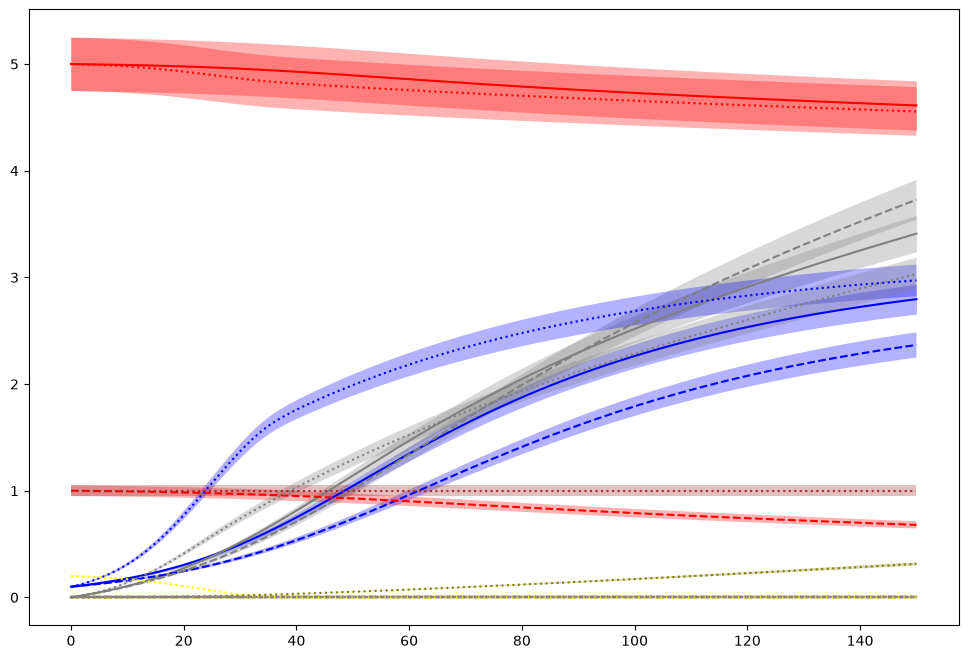

In [5]:
PARAMETERSET_COMMUNITY_Se_changed = [
    # S. elongatus
    0.15,       # u_max_Se
    1,        # k_L_Se
    1,       # e_Se
    0.3,       # k_N_Se
    10.0,        # Y_Se_N
    0.005,      # k_death_Se
    0.1,        # alpha_Suc_Se
    0.01,        # k_Met1_Se
    7,         # Y_Se_Met1
    0.001,        # beta_Met2_Se
    2,        # k_P1_Met2_Se
    0.2,        # K_I_pH_Suc_exp   
]

start_condition_axenic_se_low_N=jnp.array(STARTCONDITION_Axenic_Se_N_low)
start_condition_axenic_se_Met1_Met2=jnp.array(STARTCONDITION_Axenic_Se_Met1_Met2)



all=["Se","Um","Sc","Suc","N","P1","Met1","Met2","pH","B"]

ode_problem_community = OdeProblem(
Community_Final_Model (parameters_Se = jnp.array(PARAMETERSET_COMMUNITY_Se_changed),
    parameters_Um = jnp.array(PARAMETERSET_COMMUNITY_Um_changed),
    parameters_Sc = jnp.array(PARAMETERSET_COMMUNITY_Sc),
    parameters_abiotic = jnp.array(PARAMETERSET_COMMUNITY_abiotic),
),
full_state=False,
max_steps= 30000,
rtol= 1e-4,
atol= 1e-7,
)

t_steps = np.linspace(0,150,200)
start_condition_axenic_se = jnp.array(STARTCONDITION_Axenic_Se)
ode_solution_community = ode_problem_community(t_steps, start_condition_axenic_se)
ode_solution_community_low_N = ode_problem_community(t_steps, start_condition_axenic_se_low_N)
ode_solution_community_Met1_Met2 = ode_problem_community(t_steps, start_condition_axenic_se_Met1_Met2)



fig, axs = plt.subplots(1, 1, figsize=(12,8))
display_ODE_COMMUNITY(t_steps, ode_solution_community,
                      all, axs, std=0.05)
display_ODE_COMMUNITY(t_steps, ode_solution_community_low_N,
                      all, axs, line="--", std=0.05)
display_ODE_COMMUNITY(t_steps, ode_solution_community_Met1_Met2,
                      all, axs, line=":", std=0.05)


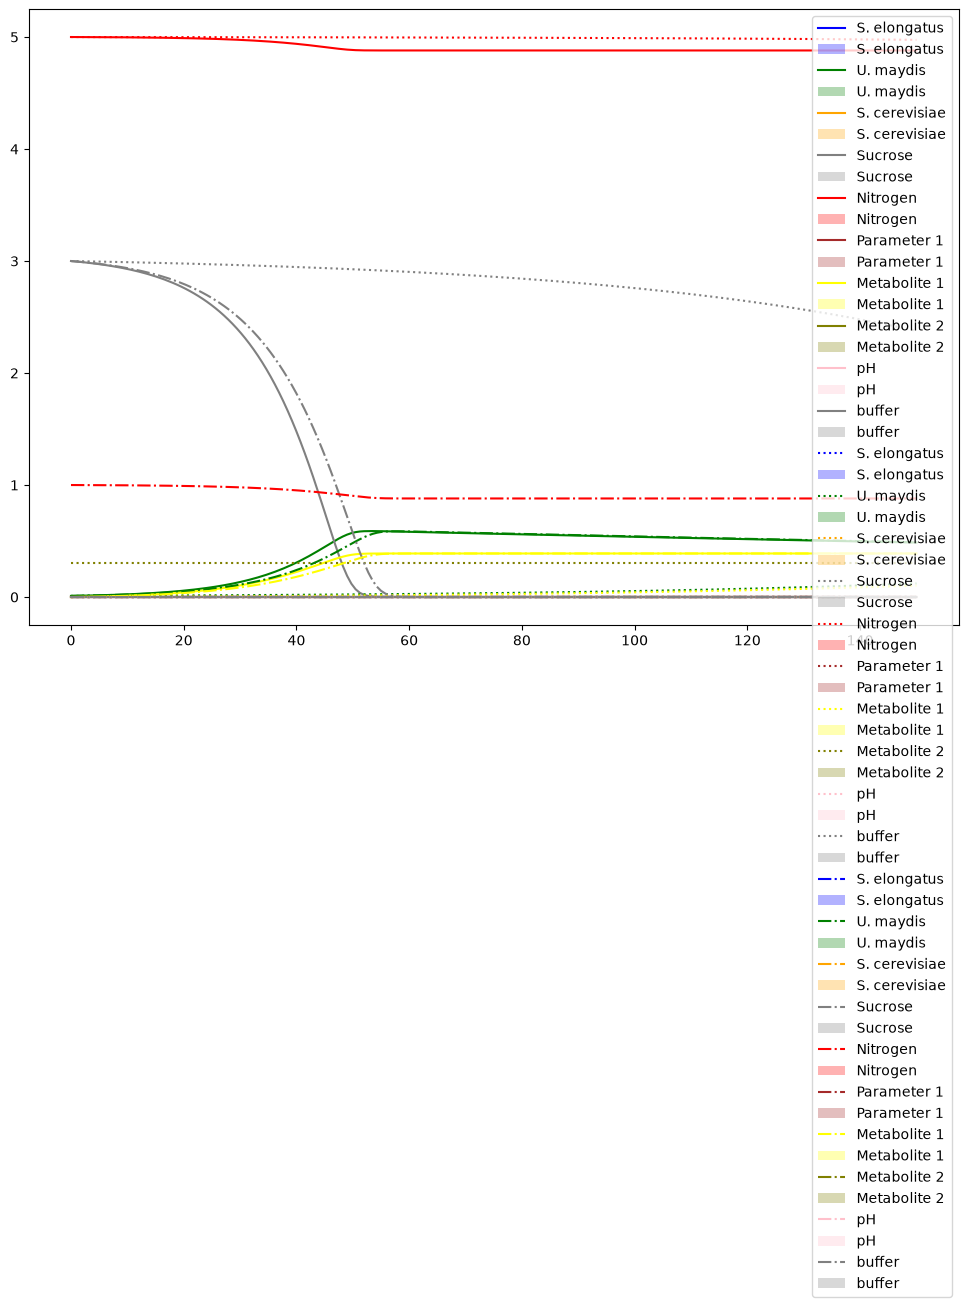

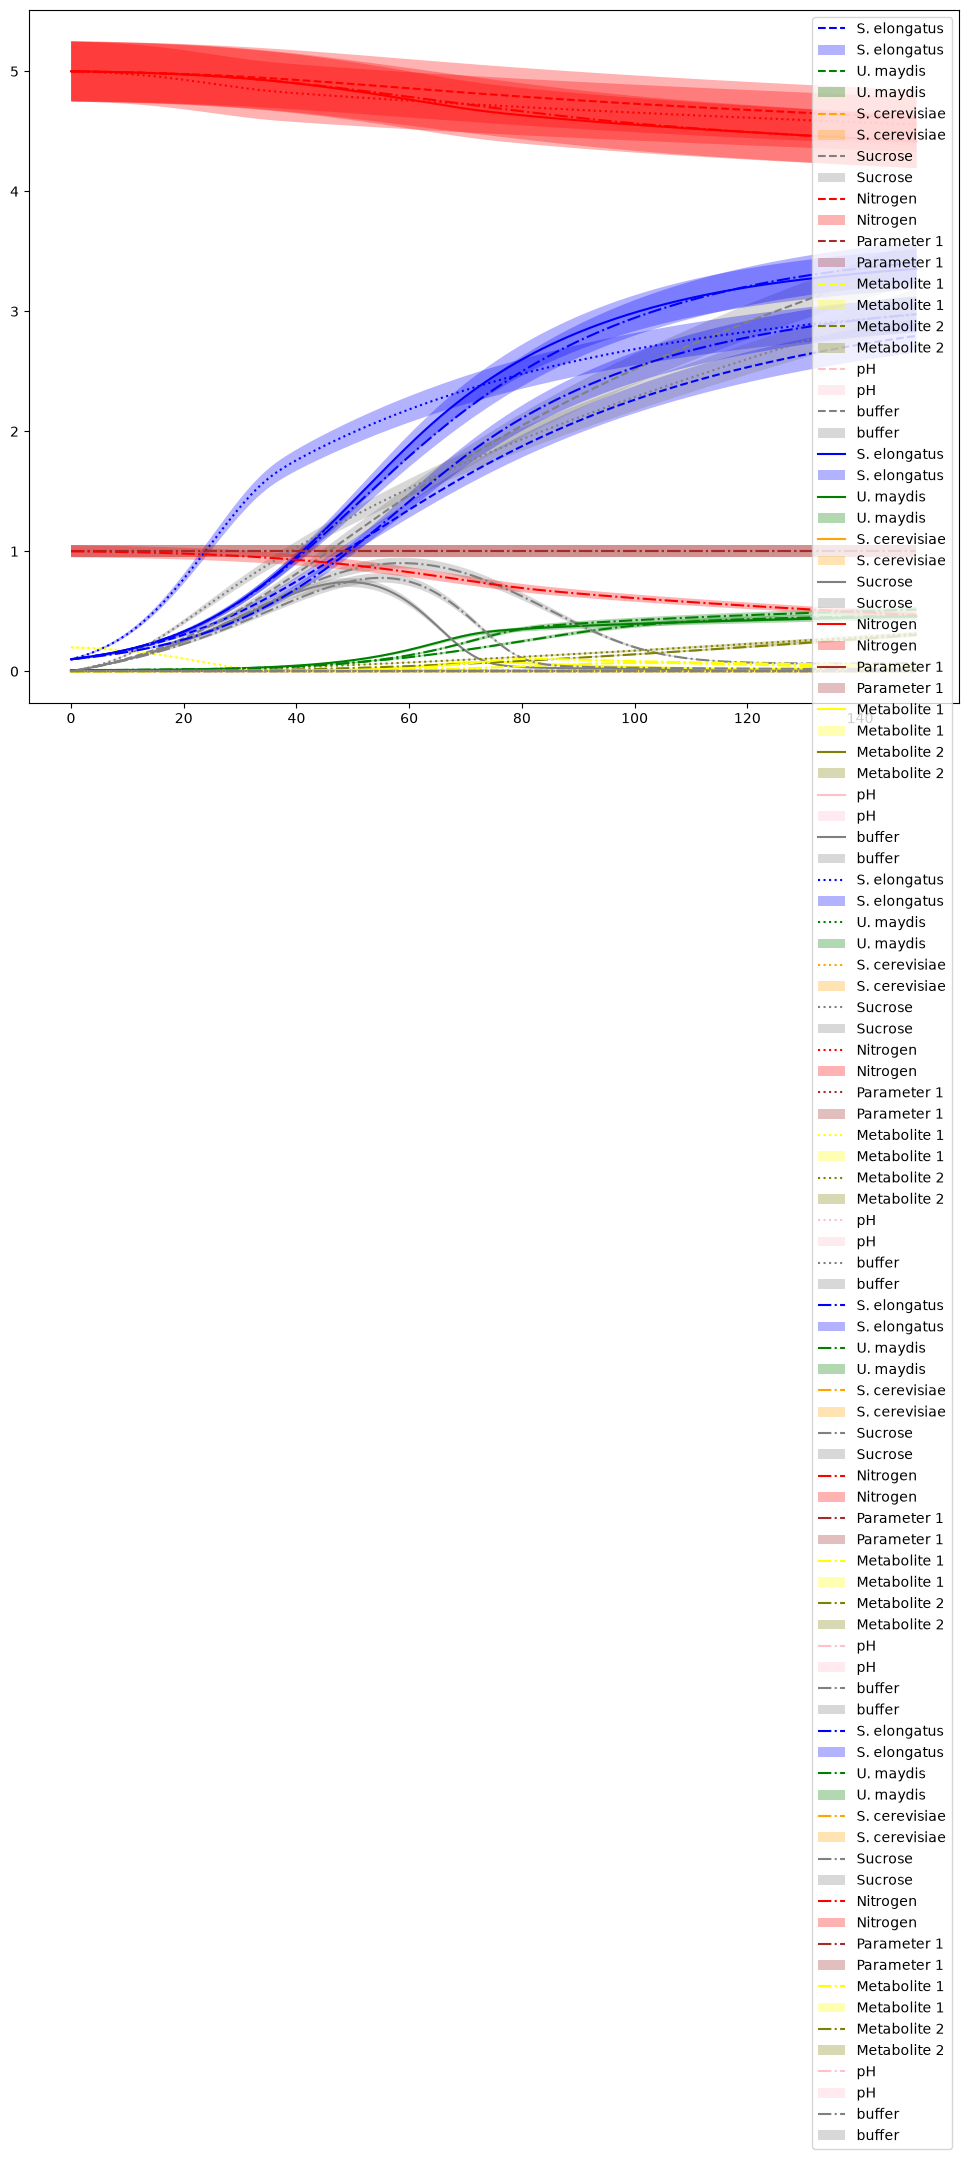

In [6]:
all=["Se","Um","Sc","Suc","N","P1","Met1","Met2","pH","B"]
ode_problem_community = OdeProblem(
Community_Final_Model (parameters_Se = jnp.array(PARAMETERSET_COMMUNITY_Se_changed),
    parameters_Um = jnp.array(PARAMETERSET_COMMUNITY_Um_changed),
    parameters_Sc = jnp.array(PARAMETERSET_COMMUNITY_Sc),
    parameters_abiotic = jnp.array(PARAMETERSET_COMMUNITY_abiotic),
),
full_state=False,
max_steps= 30000,
rtol= 1e-4,
atol= 1e-7,
)

start_condition_axenic_um=jnp.array(STARTCONDITION_Axenic_Um)
start_condition_coculture_se_um=jnp.array(STARTCONDITION_Coculture_Se_Um)
start_condition_axenic_se=jnp.array(STARTCONDITION_Axenic_Se)
start_condition_coculture_P1= jnp.array(STARTCONDITION_Coculture_Se_Um_P1)
start_condition_axenic_um_Met2= jnp.array(STARTCONDITION_Axenic_Um_Met2)
start_condition_axenic_um_N_low= jnp.array(STARTCONDITION_Axenic_Um_N_low)
start_condition_coculture_low_N= jnp.array(STARTCONDITION_Coculture_low_N)

ode_solution_axenic_um = ode_problem_community(t_steps, start_condition_axenic_um)
ode_solution_axenic_um_Met = ode_problem_community(t_steps, start_condition_axenic_um_Met2)
ode_solution_coculture_se_um = ode_problem_community(t_steps, start_condition_coculture_se_um)
ode_solution_axenic_se = ode_problem_community(t_steps, start_condition_axenic_se)
ode_solution_coculture_P1 = ode_problem_community(t_steps, start_condition_coculture_P1)
ode_solution_axenic_Um_N_low = ode_problem_community(t_steps,start_condition_axenic_um_N_low)
ode_solution_coculture_low_N= ode_problem_community(t_steps,start_condition_coculture_low_N)


fig, axs = plt.subplots(1, 1, figsize=(12,8))
display_ODE_COMMUNITY(t_steps, ode_solution_axenic_um,
                      all, axs)
display_ODE_COMMUNITY(t_steps, ode_solution_axenic_um_Met,
                      all, axs, line= ":")
display_ODE_COMMUNITY(t_steps, ode_solution_axenic_Um_N_low,
                      all, axs, line= "-.")
plt.legend()



fig, axs = plt.subplots(1,1, figsize=(12,9))

display_ODE_COMMUNITY(t_steps, ode_solution_axenic_se,
                      all, axs, line= "--", std=0.05)
display_ODE_COMMUNITY(t_steps, ode_solution_coculture_se_um,
                      all, axs, line= "-", std=0.05)
display_ODE_COMMUNITY(t_steps, ode_solution_community_Met1_Met2,
                      all, axs, line=":", std=0.05)
display_ODE_COMMUNITY(t_steps, ode_solution_coculture_P1,
                      all, axs, line="-.", std=0.05)
display_ODE_COMMUNITY(t_steps, ode_solution_coculture_low_N,
                      all, axs, line="-.", std=0.05)
plt.legend()


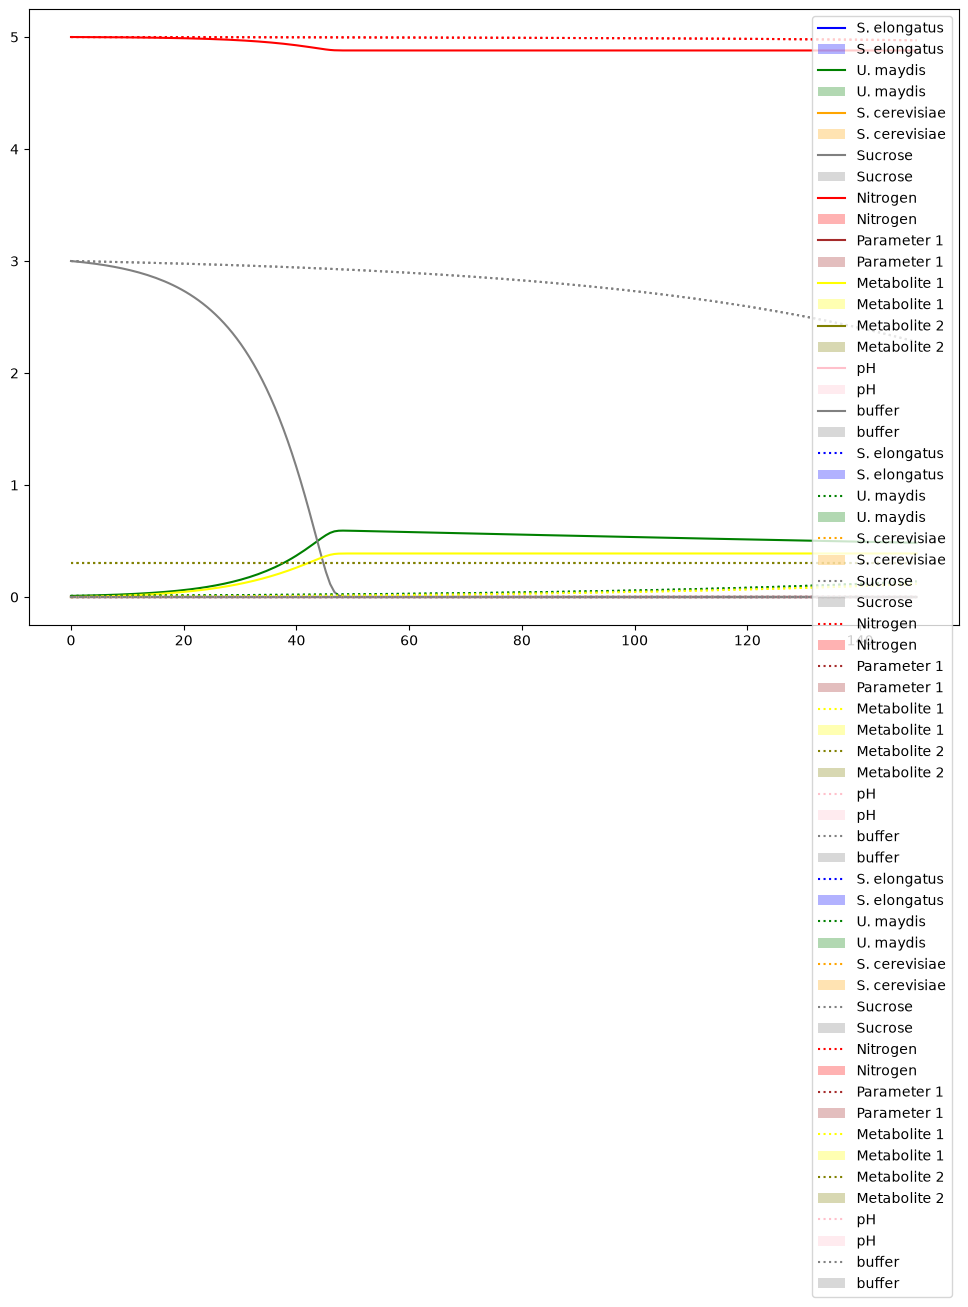

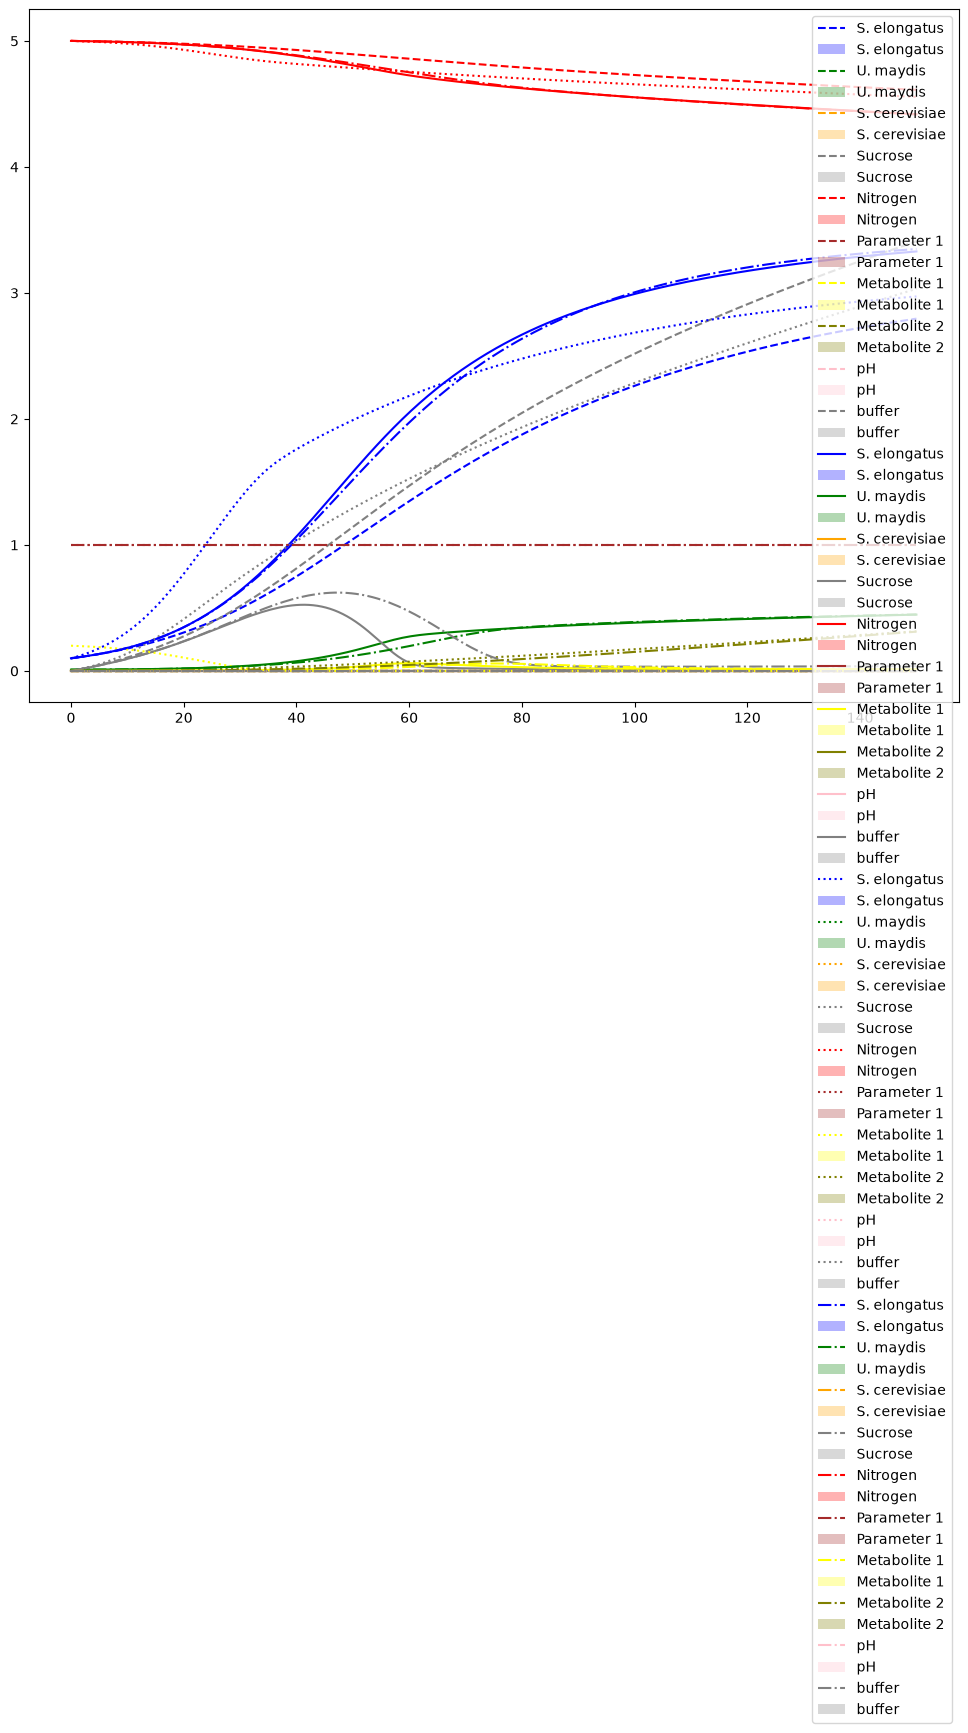

In [7]:
PARAMETERSET_COMMUNITY_Um_changed = [
    # U.maydis
    0.1,    # u_max_Um
    0.15,   # k_Suc_Um
    0.2,   # Y_Um_Suc
    0.1,    # k_N_Um
    5.0,   # Y_N_Um
    0.002,  # k_death_Um
    0.3,    # e_Um
    0.9,    # beta_Met1_Um
    0.5,    # K_I_Met1_Um
    0.08,    # K_I_Met2_Um
]



all=["Se","Um","Sc","Suc","N","P1","Met1","Met2","pH","B"]
ode_problem_community = OdeProblem(
Community_Final_Model (parameters_Se = jnp.array(PARAMETERSET_COMMUNITY_Se_changed),
    parameters_Um = jnp.array(PARAMETERSET_COMMUNITY_Um_changed),
    parameters_Sc = jnp.array(PARAMETERSET_COMMUNITY_Sc),
    parameters_abiotic = jnp.array(PARAMETERSET_COMMUNITY_abiotic),
),
full_state=False,
max_steps= 30000,
rtol= 1e-4,
atol= 1e-7,
)

start_condition_axenic_um=jnp.array(STARTCONDITION_Axenic_Um)
start_condition_coculture_se_um=jnp.array(STARTCONDITION_Coculture_Se_Um)
start_condition_axenic_se=jnp.array(STARTCONDITION_Axenic_Se)
start_condition_coculture_P1= jnp.array(STARTCONDITION_Coculture_Se_Um_P1)
start_condition_axenic_um_Met2= jnp.array(STARTCONDITION_Axenic_Um_Met2)

ode_solution_axenic_um = ode_problem_community(t_steps, start_condition_axenic_um)
ode_solution_axenic_um_Met = ode_problem_community(t_steps, start_condition_axenic_um_Met2)
ode_solution_coculture_se_um = ode_problem_community(t_steps, start_condition_coculture_se_um)
ode_solution_axenic_se = ode_problem_community(t_steps, start_condition_axenic_se)
ode_solution_coculture_P1 = ode_problem_community(t_steps, start_condition_coculture_P1)


fig, axs = plt.subplots(1, 1, figsize=(12,8))
display_ODE_COMMUNITY(t_steps, ode_solution_axenic_um,
                      all, axs)
display_ODE_COMMUNITY(t_steps, ode_solution_axenic_um_Met,
                      all, axs, line= ":")
display_ODE_COMMUNITY(t_steps, ode_solution_axenic_um_Met,
                      all, axs, line= ":")
plt.legend()

fig, axs = plt.subplots(1,1, figsize=(12,9))

display_ODE_COMMUNITY(t_steps, ode_solution_axenic_se,
                      all, axs, line= "--")
display_ODE_COMMUNITY(t_steps, ode_solution_coculture_se_um,
                      all, axs, line= "-")
display_ODE_COMMUNITY(t_steps, ode_solution_community_Met1_Met2,
                      all, axs, line=":")
display_ODE_COMMUNITY(t_steps, ode_solution_coculture_P1,
                      all, axs, line="-.")
plt.legend()


In [8]:
# generate noise:
def get_timepoint_indices (time_in_hours: list):
    indices=[]
    for x, timepoint in enumerate(time_in_hours):
        indices.append(int(200/150*timepoint))
    return indices

def add_noise (data:Array, std_dev, key):
    return data*(1+std_dev*jr.normal(key,data.shape)) 
    

six=get_timepoint_indices([0,24,48,72,96,144])
ten=get_timepoint_indices([0,8,24,32,48,56,72,80,96,144])
twentyfour=get_timepoint_indices(np.linspace(0,144,24))

ode_solution_coculture_P1[six,:]

key = jr.PRNGKey(42)
key_1,key_2 = jr.split(key)

add_noise(ode_solution_coculture_P1[twentyfour,:], 0.05 ,key_1)




Array([[1.00379623e-01, 9.75682866e-03, 0.00000000e+00, 0.00000000e+00,
        5.07510138e+00, 1.01551747e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00],
       [1.44491062e-01, 1.07346205e-02, 0.00000000e+00, 5.41082956e-02,
        4.98983240e+00, 9.65660453e-01, 6.14598976e-04, 7.41021300e-04,
        0.00000000e+00, 0.00000000e+00],
       [1.86324388e-01, 1.33504169e-02, 0.00000000e+00, 1.26753822e-01,
        5.03662062e+00, 1.04253900e+00, 1.91620726e-03, 1.83180859e-03,
        0.00000000e+00, 0.00000000e+00],
       [3.21575254e-01, 1.78123005e-02, 0.00000000e+00, 2.21234828e-01,
        4.81229019e+00, 1.04632080e+00, 2.94444198e-03, 3.45787499e-03,
        0.00000000e+00, 0.00000000e+00],
       [4.75192189e-01, 2.40432397e-02, 0.00000000e+00, 3.55633974e-01,
        5.03135109e+00, 9.99850988e-01, 3.92983807e-03, 5.74989524e-03,
        0.00000000e+00, 0.00000000e+00],
       [6.63836539e-01, 4.06890027e-02, 0.00000000e+00, 4.73186553e-01,
   

In [ ]:


class CORE_no_Met1 (eqx.Module):
    
    """
        State Vector ( Components)
                --------------------------------
                Se: S. elongatus
                Um: U. maydis
                Suc: Sucrose
                N: Nitrogen
                P1: Parameter1
                Met1: Metabolite1
                Met2: Metabolite2
            
            Parameter vectors
                ---------------------------------
                    
                    parameters_Se: Array
                    -----------------------------
                    u_max_Se, k_L_Se, e_Se,  k_N_Se, Y_Se_N, k_death_Se,
                    beta_Suc_Se, k_Met1_Se, beta_Met2_Se, k_P1_Met2_Se, K_I_pH_Suc_exp
                     
                    parameters_Um: Array
                    -----------------------------
                    u_max_Um, k_Suc_Um, Y_Um_Suc, k_N_Um,Y_Um_N, k_death_Um,
                    e_Um, beta_Met1_Um, K_I_Met1_Um, K_I_Met2_Um, k_Met2_Um
                    
                    parameters_abiotic: Array
                    -----------------------------
                    L_0, Suc_Feed
                
            
            weights: Array
    """
    parameters_Se: Array
    parameters_Um: Array
    parameters_Sc: Array
    parameters_abiotic: Array

    def __call__(self, t: float, variables: Array, args) -> Array:
        
        # parameters and variables:
        # ----------------------------------------------------
        Se,Um,Sc,Suc,N,P1,Met1,Met2,pH,B = variables
        u_max_Se, k_L_Se, e_Se,  k_N_Se, Y_Se_N, k_death_Se, alpha_Suc_Se, k_Met1_Se, Y_Se_Met1, beta_Met2_Se, k_P1_Met2_Se, K_I_pH_Suc_exp = self.parameters_Se
        u_max_Um,k_Suc_Um, Y_Um_Suc, k_N_Um,Y_Um_N, k_death_Um, e_Um, beta_Met1_Um, K_I_Met1_Um, K_I_Met2_Um = self.parameters_Um
        u_max_Sc, k_Suc_Sc, Y_Sc_Suc, k_N_Sc, Y_N_Sc, k_death_Sc, e_Sc, alpha_H_Sc = self.parameters_Sc
        L_0, e_medium, K_B,= self.parameters_abiotic
    
        # derived
        L = L_0 * jnp.exp(-Se*e_Se - Um*e_Um - Sc*e_Sc - e_medium)
        
        # growth of Se
        u_Se    = u_max_Se * (L /(k_L_Se + L)) * (N/(k_N_Se+N)) # * (1+(Met1/(k_Met1_Se+Met1)))
        #Met1_imp_Se = Se * u_Se * (Met1/(k_Met1_Se+Met1))/Y_Se_Met1
        Met2_exp_Se = Se * beta_Met2_Se * P1
        Suc_exp_Se  = Se * alpha_Suc_Se * L * (K_I_pH_Suc_exp / (K_I_pH_Suc_exp + pH))
    
        #Saccharomyces Cerevisiae
        u_Sc           = u_max_Sc * (Suc /(k_Suc_Sc + Suc)) * (N/(k_N_Sc+N))
        Suc_imp_Sc     = u_Sc * Sc * 1/Y_Sc_Suc
        exp_pH_Sc       = Sc * u_Sc * alpha_H_Sc
        
        # growth of Um
        u_Um    = u_max_Um * (Suc /(k_Suc_Um + Suc)) * (N/(k_N_Um+N)) * (K_I_Met2_Um/(K_I_Met2_Um + Met2))
        Suc_imp_Um = u_Um * Um * 1/Y_Um_Suc
        # Met1_exp_Um = Um * u_Um * beta_Met1_Um * (K_I_Met1_Um/(Met1+K_I_Met1_Um))
        
        # change of variables
        #---------------------------------------------------------
        
        dSedt       = Se * (u_Se - k_death_Se)
        dUmdt       = Um * (u_Um - k_death_Um)
        dScdt       = Sc * (u_Sc - k_death_Sc)
        
        # paramters, metabolites, etc. (ressources)
        dSucdt      = Suc_exp_Se -Suc_imp_Um
        dNdt        = -u_Se*Se * 1/Y_Se_N - u_Um*Um * 1/Y_Um_N
        dP1dt       = 0.0
        dMet1dt     = 0.0 #Met1_exp_Um - Met1_imp_Se
        dMet2dt     = Met2_exp_Se
        dBdt        = - exp_pH_Sc*((B+K_B)/K_B)
        dpHdt       = exp_pH_Sc*(K_B/(K_B+B))
        

        return jnp.array([dSedt,dUmdt,dScdt,dSucdt,dNdt,dP1dt,dMet1dt,dMet2dt,dpHdt,dBdt])


# ODE-term:
key = jr.PRNGKey(42)
model_key, loader_key, key_1, key_2, key_3, key_4, key_5 = jr.split(key, 7)

ode_core = CORE_no_Met1 (parameters_Se = jnp.array(PARAMETERSET_COMMUNITY_Se_changed),
    parameters_Um = jnp.array(PARAMETERSET_COMMUNITY_Um_changed),
    parameters_Sc = jnp.array(PARAMETERSET_COMMUNITY_Sc),
    parameters_abiotic = jnp.array(PARAMETERSET_COMMUNITY_abiotic),
)

nde = NDE(in_size=10, out_size=10, width_size=16, depth=2, key= model_key)

ude = UDE(ode=ode_core, nde=nde, operator="add", lambda_= 0.1, constraint="tanh" )

ude_community = UDE_Community(ode=ode_core, nde=nde, lambda_= 0.1)

problem = OdeProblem(ude, 
    full_state=True,
    rtol= 1e-3,
    atol=1e-6,
    max_steps=300000
)

CommunityProblem = OdeProblem(
    ude_community, 
    full_state=True,
    rtol= 1e-3,
    atol=1e-6,
    max_steps=300000
)

# generate noise:
def get_timepoint_indices (time_in_hours: list):
    indices=[]
    for x, timepoint in enumerate(time_in_hours):
        indices.append(int(200/150*timepoint))
    return indices

def add_noise (data:Array, std_dev, key):
    return data*(1+std_dev*jr.normal(key,data.shape)) 
    

six=get_timepoint_indices([0,24,48,72,96,144])
ten=get_timepoint_indices([0,8,24,32,48,56,72,80,96,144])
twentyfour=get_timepoint_indices(np.linspace(0,144,24))

ode_solution_coculture_P1[six,:]

# what should the UDE see
list_ys=[]
list_y0=[]
for ys in [ode_solution_axenic_um, ode_solution_axenic_um_Met, ode_solution_coculture_se_um, ode_solution_axenic_se, ode_solution_coculture_P1]:
    ys_noise = add_noise(ys[twentyfour,:], 0.05 ,key_1)
    list_ys.append(ys_noise)
    list_y0.append(ys_noise[0])

data_train= jnp.array(list_ys)
ts_train= t_steps[twentyfour]
y0_full = jnp.array(list_y0)

max_values = jnp.max(data_train, axis=(0,1))
scale = jnp.where(max_values == 0, 1.0, max_values)

scale
print("scale:", scale)
print("type:", type(scale))

scale: [3.6625082  0.6158012  1.         3.3543298  5.432948   1.1088628
 0.41753817 0.3270444  1.         1.        ]
type: <class 'jaxlib._jax.ArrayImpl'>


In [10]:
ODE_problem = OdeProblem(ode_core,
    full_state=True,
    rtol= 1e-3,
    atol=1e-6,
    max_steps=300000
)

ODE_problem(t_steps, start_condition_axenic_um )


Array([[0.        , 0.01      , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.01071297, 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.01147676, 0.        , ..., 0.        , 0.        ,
        0.        ],
       ...,
       [0.        , 0.48576134, 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.48503017, 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.4842995 , 0.        , ..., 0.        , 0.        ,
        0.        ]], dtype=float32)

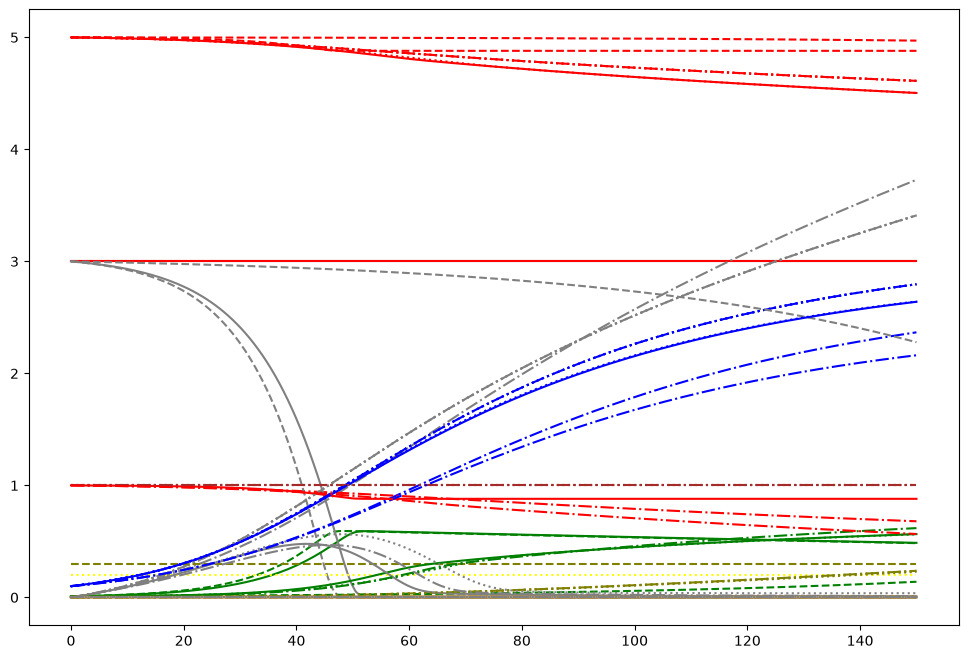

In [11]:
fig, axs = plt.subplots(1, 1, figsize=(12,8))
linesstyles = ["-", ":", "-.", "--",]
i=0
for name,start_condition in conditions_df.iterrows():
    linestyle = i%4
    ys=ODE_problem(t_steps,jnp.array(start_condition))
    display_ODE_COMMUNITY(t_steps, ys,
        all, axs, line=linesstyles[linestyle])
    i += 1  

Erkenntnisse:
1. ode_core kann auf allem laufen
Was könnte es noch sein?
2. falscher Parametersatz zu beginn !
test: richtige parameter einfrieren und dann nur NDE trainieren


In [12]:
from jax import config

config.update("jax_debug_nans", True)
config.update("jax_debug_infs", True)

In [13]:
import jax.tree_util as jtu
filter_spec = jtu.tree_map(lambda _: False, problem)
filter_spec = eqx.tree_at(
        lambda tree: tree.rhs.nde,
        filter_spec,
        replace=jtu.tree_map(lambda _: True, problem.rhs.nde),
    )



NameError: name 'problem' is not defined

In [ ]:
problem.rhs.nde.mlp.layers[-1]

Linear(
  weight=f32[10,16],
  bias=f32[10],
  in_features=16,
  out_features=10,
  use_bias=True
)

In [ ]:
final_layer = problem.rhs.nde.mlp.layers[-1]
new_weights = jnp.zeros_like(final_layer.weight)
new_bias = jnp.zeros_like(final_layer.bias)
problem = eqx.tree_at(
    lambda tree: (tree.rhs.nde.mlp.layers[-1].weight, tree.rhs.nde.mlp.layers[-1].bias),
    problem,
    (new_weights, new_bias)
)

Ideen von Gemini:
1. Learning rate anpassen


Was genau passiert in Schritt 2?

1. Schritt 1 (Initialisierung): Dein Netzwerk ist perfekt auf Null initialisiert. Diffrax löst die reine, perfekte ODE ohne Probleme. Der Loss-Wert wird berechnet.
2. Der Gradienten-Schritt: Der Optimierer berechnet die Gradienten und aktualisiert die Gewichte des Netzwerks zum ersten Mal.
3. Schritt 2 (Der Absturz): Da das Netzwerk im ersten Schritt noch unreguliert ist, schlägt der Optimierer oft viel zu heftig aus. Das Netzwerk gibt plötzlich für bestimmte Zustände extreme Werte (oder völlig falsche Steigungen) aus.
4. Die Reaktion von Diffrax: Dein adaptiver Solver (z. B. Tsit5 oder Dopri5) merkt, dass der Fehler im Integral explodiert. Er verkleinert die Schrittweite (dt) drastisch, um die Kurve noch sauber zu kriegen. Wenn das Netzwerk aber "Unsinn" ausgibt, wird dt infinitesimal klein. Der Solver versucht es immer und immer wieder, bis er das standardmäßige Limit (max_steps=4096) oder dein eingestelltes Limit von 100.000 Schritten erreicht – und bricht mit dem RuntimeError ab.

🛠️ 4 Sofortmaßnahmen, um den Fehler zu beheben

Hier sind die vier Stellschrauben in Diffrax und JAX, mit denen du das Problem sofort in den Griff bekommst:

1. Lernrate (Learning Rate) drastisch senken

Das ist der häufigste Auslöser für den Fehler in Schritt 2. Wenn deine Lernrate (z. B. in Optax) bei 1e-3 liegt, senke sie testweise massiv ab (z. B. auf 1e-5 oder 1e-6). Dadurch veränderst du das perfekt genullte Netzwerk im ersten Schritt nur minimal, und der Solver explodiert nicht direkt.

2. Das Netzwerk clippen / beschränken

Da das neuronale Netzwerk (MLP) am Anfang unkontrolliert riesige Werte ausgeben kann, zwinge es mathematisch dazu, eine kleine Korrektur zu bleiben. Du kannst die Ausgabe deines Netzwerks im Vektorfeld mithilfe von jnp.tanh beschränken:
python
def ude_vector_field(t, y, args):
    neural_net = args
    dx_physics = perfect_ode(t, y)
    
    # Die maximale Korrektur des Netzwerks wird hart auf z.B. +/- 0.5 begrenzt
    dx_correction = 0.5 * jnp.tanh(neural_net(y))
    
    return dx_physics + dx_correction
Verwende Code mit Vorsicht.

3. Wechsel auf einen impliziten (steifen) Solver

Wenn dein physikalisches System durch das Netzwerk "steif" (stiff) wird (d. h. es entstehen extrem schnelle Dynamiken neben langsamen Dynamiken), versagen explizite Solver wie Tsit5. Nutze stattdessen einen impliziten Solver wie Kvaerno5 oder Sdirk4R:
python
import diffrax

# Implizite Solver benötigen einen Root-Finder für die impliziten Schritte
solver = diffrax.Kvaerno5() 
Verwende Code mit Vorsicht.

4. jax_enable_x64 aktivieren

Standardmäßig läuft JAX in 32-Bit-Präzision (float32). Bei Differentialgleichungen führt das extrem schnell zu numerischer Instabilität (Unterlauf/Überlauf). Füge ganz oben in deinem Skript Folgendes hinzu:
python
from jax import config
config.update("jax_enable_x64", True)
Verwende Code mit Vorsicht.
Hinweis: Wenn du float64 aktivierst, stelle sicher, dass deine Daten und die Initialisierung des Netzwerks ebenfalls jnp.float64 nutzen.

Was du jetzt tun kannst:

Erhöhe nicht einfach max_steps weiter auf 1.000.000 – das verlangsamt nur das Training und löst die mathematische Ursache nicht.
Welchen Solver (z. B. Tsit5) und welche Lernrate nutzt du aktuell in deinem Setup? Wenn du mir kurz den Code deines Optimierers zeigst, können wir die Lernrate direkt stabil einstellen.


In [ ]:
EQX_ON_ERROR=breakpoint
trained_ude = train_model(
    problem,
    data=data_train,          # shape (1, T_train, 2)
    y0=y0_full,               # shape (1, 7)
    ts_train=ts_train,
    loader_key=loader_key,
    steps_strategy=(14,),
    length_strategy=(1.0,),
    learning_rate=1e-5,
    print_every=1,
    scale=scale,
    filter_spec=filter_spec
)


── Phase 1/1 (14 steps, t ∈ [0.00, 144.72]) ──
  Step     0 | Loss 0.005188 | Time 2.537s
  Step     1 | Loss 0.001956 | Time 2.528s
  Step     2 | Loss 0.007760 | Time 0.005s
  Step     3 | Loss 0.000364 | Time 0.002s
  Step     4 | Loss 0.063984 | Time 0.010s
  Step     5 | Loss 2054564.250000 | Time 0.006s
  Step     6 | Loss 0.000364 | Time 0.003s
  Step     7 | Loss 0.001956 | Time 0.002s
  Step     8 | Loss 0.007760 | Time 0.004s
  Step     9 | Loss 0.005182 | Time 0.010s
  Step    10 | Loss 0.063984 | Time 0.012s
  Step    11 | Loss 0.001956 | Time 0.002s
  Step    12 | Loss 0.005182 | Time 0.008s
  Step    13 | Loss 0.000364 | Time 0.002s


### Es klappt für ein paar versuche, wenn NDE sehr stark beschränkt wird. Aber wahrscheinlich problem mit ODE

In [ ]:
problem.rhs.nde

NDE(
  out_scale=weak_f32[],
  mlp=MLP(
    layers=(
      Linear(
        weight=f32[16,10],
        bias=f32[16],
        in_features=10,
        out_features=16,
        use_bias=True
      ),
      Linear(
        weight=f32[16,16],
        bias=f32[16],
        in_features=16,
        out_features=16,
        use_bias=True
      ),
      Linear(
        weight=f32[10,16],
        bias=f32[10],
        in_features=16,
        out_features=10,
        use_bias=True
      )
    ),
    activation=<PjitFunction of <function silu at 0x0000027C8AC28EA0>>,
    final_activation=<function <lambda>>,
    use_bias=True,
    use_final_bias=True,
    in_size=10,
    out_size=10,
    width_size=16,
    depth=2
  )
)